# DBSCAN Clustering of Retail Bricks
**Dataset:** `Dummy_Retail_Profits_Unpivoted.csv` – 1,097 bricks × 7 packs × 60 months (Aug-2021 → Jul-2026), three companies, eight Australian states/territories.

**Objective:** find density-based groups of bricks *and* identify outlier bricks that do not fit any group – something K-means cannot do (it forces every point into a cluster).

**Approach:** same cleaning, features and scaling as the K-means notebook (so results are comparable) → clustering-tendency check → choose `eps` / `min_samples` with the k-distance plot and a parameter grid → fit → evaluate (silhouette on clustered points, Davies-Bouldin, Calinski-Harabasz, noise %, coverage) → analyse the noise bricks → sensitivity & stability → validate against state → save artefacts.

Each code cell is followed by a short **Insight** note interpreting its output.

## 1. Setup

In [1]:
%matplotlib inline
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.stats import chi2_contingency

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

# Data location: current folder first, then the Copilot upload folder
CANDIDATES = ["Dummy_Retail_Profits_Unpivoted.csv", "/mnt/user-data/uploads/Dummy_Retail_Profits_Unpivoted.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
os.makedirs("artifacts", exist_ok=True)
print("Using:", DATA_PATH)

Using: /mnt/user-data/uploads/Dummy_Retail_Profits_Unpivoted.csv


## 2. Load the data
The file is an *unpivoted* (long) retail sell-out extract: one row per **Brick × Pack × Month**. We inspect structure and data types before touching anything.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print(df.dtypes.to_string())
print("\nUnique values -> bricks:", df["Brick Name"].nunique(), "| states:", df["State"].nunique(),
      "| companies:", df["Company"].nunique(), "| packs:", df["Pack"].nunique(), "| months:", df["Month"].nunique())

Shape: (460740, 8)


,Brick Name,State,Company,Pack,Month,Year,MonthNum,Units
0,Brick 0001,QLD,Company A,Product A,Aug-2021,2021,8,10
1,Brick 0001,QLD,Company A,Product A,Sep-2021,2021,9,10
2,Brick 0001,QLD,Company A,Product A,Oct-2021,2021,10,13
3,Brick 0001,QLD,Company A,Product A,Nov-2021,2021,11,10
4,Brick 0001,QLD,Company A,Product A,Dec-2021,2021,12,12


Brick Name    object
State         object
Company       object
Pack          object
Month         object
Year           int64
MonthNum       int64
Units         object

Unique values -> bricks: 1097 | states: 8 | companies: 3 | packs: 7 | months: 60


> **Insight —** The file has 460,740 rows = 1,097 bricks × 7 packs × 60 months, so it is a complete panel. `Units` was read as text (object) because missing sales are stored as `-`; this must be fixed before any maths.

## 3. Data cleaning & validation
`Units` is read as text because missing sales are written as `"-"`. In sell-out data a dash means *no units sold that month*, so it is converted to **0** (not dropped). We then verify the panel is complete and consistent.

In [3]:
dash_n = (df["Units"] == "-").sum()
print(f"'-' entries: {dash_n:,} ({dash_n/len(df):.1%} of rows) -> converted to 0")
df["Units"] = pd.to_numeric(df["Units"].replace("-", 0)).astype(int)
df["Date"] = pd.to_datetime(df["Month"], format="%b-%Y")

n_b, n_p, n_m = df["Brick Name"].nunique(), df["Pack"].nunique(), df["Date"].nunique()
checks = pd.Series({
    "Date range": f"{df['Date'].min():%b-%Y} to {df['Date'].max():%b-%Y}",
    "Rows (actual)": len(df),
    "Rows (expected = bricks x packs x months)": n_b * n_p * n_m,
    "Duplicate Brick-Pack-Month rows": int(df.duplicated(["Brick Name", "Pack", "Date"]).sum()),
    "Negative unit values": int((df["Units"] < 0).sum()),
    "Bricks mapped to >1 state": int((df.groupby("Brick Name")["State"].nunique() > 1).sum()),
    "Missing values (any column)": int(df.isna().sum().sum()),
})
display(checks.to_frame("Check"))

'-' entries: 91,234 (19.8% of rows) -> converted to 0


,Check
Date range,Aug-2021 to Jul-2026
Rows (actual),460740
Rows (expected = bricks x packs x months),460740
Duplicate Brick-Pack-Month rows,0
Negative unit values,0
Bricks mapped to >1 state,0
Missing values (any column),0


> **Insight —** 19.8 % of rows (91,234) are dashes, now treated as zero sales. The panel is complete (actual rows = expected rows) with no duplicates, negatives or missing values, and every brick maps to exactly one state – the data is clean enough to model without row removal.

## 4. Exploratory data analysis
Before engineering features we look at how units are distributed across packs, companies, states and time.

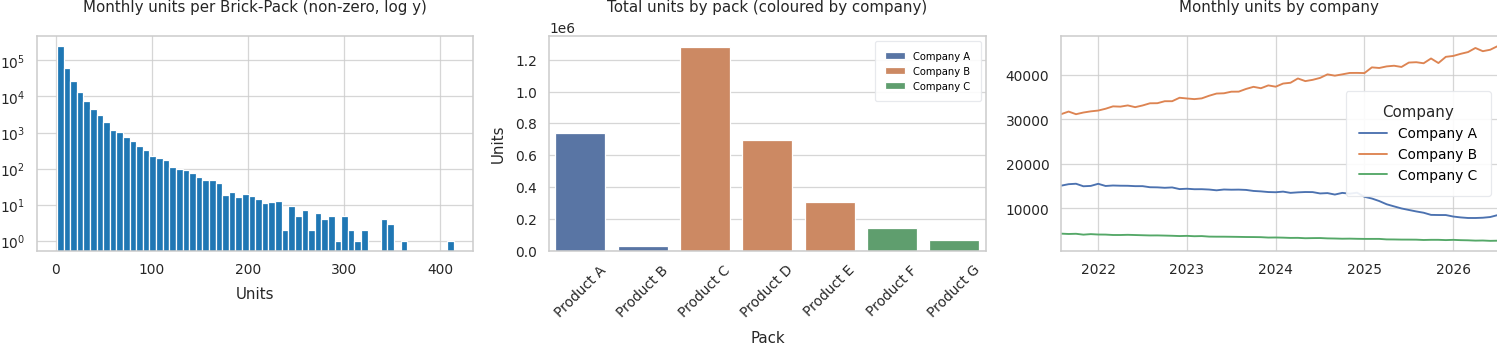

,Company,Pack,Units,ZeroShare
0,Company A,Product A,"738,054",0.8%
1,Company A,Product B,"27,002",80.9%
2,Company B,Product C,"1,282,906",0.1%
3,Company B,Product D,"696,127",0.6%
4,Company B,Product E,"306,582",3.8%
5,Company C,Product F,"140,732",15.5%
6,Company C,Product G,"67,832",36.8%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
nz = df.loc[df["Units"] > 0, "Units"]
ax[0].hist(nz, bins=60, color="#1f77b4"); ax[0].set_yscale("log")
ax[0].set_title("Monthly units per Brick-Pack (non-zero, log y)"); ax[0].set_xlabel("Units")

pack_tbl = df.groupby(["Company", "Pack"]).agg(Units=("Units", "sum"), ZeroShare=("Units", lambda s: (s == 0).mean())).reset_index()
sns.barplot(data=pack_tbl, x="Pack", y="Units", hue="Company", dodge=False, ax=ax[1])
ax[1].set_title("Total units by pack (coloured by company)"); ax[1].tick_params(axis="x", rotation=45); ax[1].legend(loc="upper right", fontsize=8)

monthly = df.groupby(["Date", "Company"])["Units"].sum().unstack()
monthly.plot(ax=ax[2]); ax[2].set_title("Monthly units by company"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

display(pack_tbl.assign(ZeroShare=lambda d: d["ZeroShare"].map("{:.1%}".format), Units=lambda d: d["Units"].map("{:,}".format)))

> **Insight —** Volume is heavily right-skewed (most brick-pack-months are under 10 units, max 414). Product C (Company B) is the biggest pack at ~1.28 M units; Product B is almost dormant (80.9 % zero months) and Product G is intermittent (36.8 %). Company B has grown steadily while Company A has fallen since 2025 and Company C is drifting down.

In [5]:
state_tbl = df.groupby("State").agg(Bricks=("Brick Name", "nunique"), Units=("Units", "sum"))
state_tbl["Share of units"] = (state_tbl["Units"] / state_tbl["Units"].sum()).map("{:.1%}".format)
state_tbl["Units per brick"] = (state_tbl["Units"] / state_tbl["Bricks"]).round(0)
display(state_tbl.sort_values("Units", ascending=False))

tot = df.groupby("Date")["Units"].sum()
yoy = tot.rolling(12).sum().pct_change(12).dropna()
print(f"Total units, last 12 months: {tot.iloc[-12:].sum():,} | previous 12 months: {tot.iloc[-24:-12].sum():,} | change: {tot.iloc[-12:].sum()/tot.iloc[-24:-12].sum()-1:+.1%}")

,Bricks,Units,Share of units,Units per brick
State,,,,
NSW,320,937467,28.8%,2930.0
VIC,260,858419,26.3%,3302.0
QLD,204,589105,18.1%,2888.0
WA,127,341727,10.5%,2691.0
SA,90,267171,8.2%,2969.0
ACT,58,172894,5.3%,2981.0
TAS,31,66669,2.0%,2151.0
NT,7,25783,0.8%,3683.0


Total units, last 12 months: 668,191 | previous 12 months: 675,278 | change: -1.0%


> **Insight —** NSW (320 bricks, 28.8 % of units) and VIC (260 bricks, 26.3 %) dominate; VIC has the highest units per brick (3,302), NT is tiny (7 bricks). Total volume in the last 12 months is 668,191 units, −1.0 % vs the prior 12 months – a flat market, so growth differences between bricks are the interesting signal.

## 5. Feature engineering (Brick level)
Clustering needs **one row per brick**. We collapse the 60-month panel into behavioural features that describe *how big*, *how fast-growing*, *how stable* and *what mix* each brick is. **State is deliberately excluded** from the model so that it can later be used as an independent check of the clusters.

| Feature | Definition | Why it matters |
|---|---|---|
| `Log_L12M` | log(1 + units, last 12 months Aug-25 to Jul-26) | Size / market potential (log tames skew) |
| `YoY_Growth` | L12M vs previous 12M, clipped to [-100%, +200%] | Momentum |
| `Trend_Slope` | OLS slope over 60 months ÷ mean monthly units | Long-run structural trend |
| `CV` | Std ÷ mean of monthly units | Volume stability / intermittency |
| `Seasonality` | Peak calendar-month average ÷ overall monthly average | Seasonal concentration |
| `Share_CompA/B/C` | Share of L12M units by company | Competitive mix |

In [6]:
months = np.sort(df["Date"].unique())
l12, p12 = months[-12:], months[-24:-12]
print("L12M window:", pd.Timestamp(l12[0]).strftime("%b-%Y"), "to", pd.Timestamp(l12[-1]).strftime("%b-%Y"),
      "| P12M window:", pd.Timestamp(p12[0]).strftime("%b-%Y"), "to", pd.Timestamp(p12[-1]).strftime("%b-%Y"))

brick_month = df.groupby(["Brick Name", "Date"])["Units"].sum().unstack()          # 1097 x 60
comp_l12 = df[df["Date"].isin(l12)].pivot_table(index="Brick Name", columns="Company", values="Units", aggfunc="sum", fill_value=0)

F = pd.DataFrame(index=brick_month.index)
F["L12M"] = brick_month[l12].sum(axis=1)
F["P12M"] = brick_month[p12].sum(axis=1)
F["Log_L12M"] = np.log1p(F["L12M"])
F["YoY_Growth"] = ((F["L12M"] - F["P12M"]) / F["P12M"]).clip(-1, 2)

t = np.arange(brick_month.shape[1])
F["Trend_Slope"] = np.array([np.polyfit(t, r, 1)[0] for r in brick_month.values]) / brick_month.mean(axis=1).values
F["CV"] = brick_month.std(axis=1) / brick_month.mean(axis=1)
F["Zero_Month_Pct"] = (brick_month == 0).mean(axis=1)

moy = brick_month.copy(); moy.columns = pd.DatetimeIndex(moy.columns).month
moy = moy.T.groupby(level=0).mean().T
F["Seasonality"] = moy.max(axis=1) / moy.mean(axis=1)

for c in ["Company A", "Company B", "Company C"]:
    F["Share_Comp" + c[-1]] = comp_l12[c] / comp_l12.sum(axis=1)
F["Pack_Breadth"] = (df[df["Date"].isin(l12)].groupby(["Brick Name", "Pack"])["Units"].sum().gt(0)
                     .groupby("Brick Name").sum())
F["State"] = df.drop_duplicates("Brick Name").set_index("Brick Name")["State"]

print("Feature table:", F.shape)
display(F.describe().T.round(3))

L12M window: Aug-2025 to Jul-2026 | P12M window: Aug-2024 to Jul-2025
Feature table: (1097, 13)


,count,mean,std,min,25%,50%,75%,max
L12M,1097.0,609.108,665.614,11.000,230.000,422.000,734.000,7513.000
P12M,1097.0,615.568,672.848,8.000,233.000,423.000,743.000,8006.000
Log_L12M,1097.0,5.998,0.934,2.485,5.442,6.047,6.600,8.925
YoY_Growth,1097.0,-0.011,0.067,-0.257,-0.056,-0.012,0.033,0.375
Trend_Slope,1097.0,0.002,0.001,-0.003,0.001,0.002,0.003,0.022
CV,1097.0,0.164,0.035,0.108,0.149,0.160,0.172,1.027
Zero_Month_Pct,1097.0,0.000,0.014,0.000,0.000,0.000,0.000,0.467
Seasonality,1097.0,1.137,0.047,1.043,1.107,1.130,1.160,1.667
Share_CompA,1097.0,0.148,0.017,0.000,0.141,0.149,0.158,0.193
Share_CompB,1097.0,0.807,0.028,0.750,0.791,0.802,0.814,1.000


> **Insight —** The 1,097-row feature table is strongly skewed: L12M median 422 vs mean 609 and max 7,513 units. YoY growth averages −1.1 % (range −25.7 % to +37.5 %); company mix is ~81 % B / ~15 % A / ~4 % C. A few bricks have extreme CV (max 1.03) and 92 bricks have no Company C sales at all – these will behave as outliers.

### 5.1 Feature selection
We check collinearity among candidate features and drop redundant ones so that no single concept is double-weighted in a distance-based model.

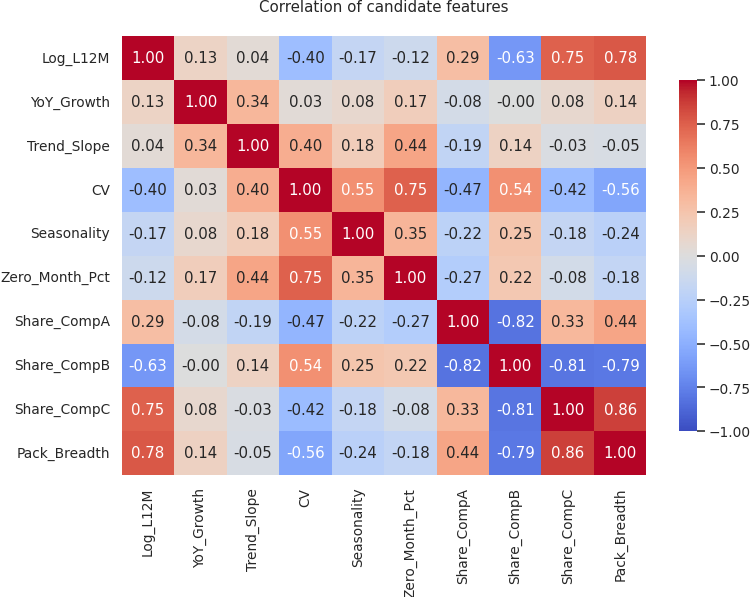

Pairs with |r| >= 0.70:
Share_CompC  Pack_Breadth      0.86
Log_L12M     Pack_Breadth      0.78
CV           Zero_Month_Pct    0.75
Log_L12M     Share_CompC       0.75
Share_CompB  Pack_Breadth     -0.79
             Share_CompC      -0.81
Share_CompA  Share_CompB      -0.82


In [7]:
cand = ["Log_L12M", "YoY_Growth", "Trend_Slope", "CV", "Seasonality", "Zero_Month_Pct",
        "Share_CompA", "Share_CompB", "Share_CompC", "Pack_Breadth"]
corr = F[cand].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .8})
plt.title("Correlation of candidate features"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pairs with |r| >= 0.70:"); print(pairs[pairs.abs() >= 0.70].sort_values(ascending=False).round(2).to_string())

> **Insight —** Size and range travel together: `Log_L12M` correlates 0.78 with `Pack_Breadth` and 0.75 with `Share_CompC` (big bricks stock the full range); volatility (`CV`) falls with size (r≈−0.48). The three company shares sum to 1 (A vs B r = −0.82), so one must go. `Pack_Breadth` and `Zero_Month_Pct` are redundant and are dropped.

In [8]:
FEATURES = ["Log_L12M", "YoY_Growth", "Trend_Slope", "CV", "Seasonality", "Share_CompA", "Share_CompC"]
dropped = {"Pack_Breadth": "r~0.78 with Log_L12M and 0.86 with Share_CompC (size / range proxy)", "Zero_Month_Pct": "r~0.75 with CV; near-constant (almost no zero months)",
           "Share_CompB": "reference category - the three shares sum to 1"}
print("Model features:", FEATURES); print("Dropped:", dropped)

Model features: ['Log_L12M', 'YoY_Growth', 'Trend_Slope', 'CV', 'Seasonality', 'Share_CompA', 'Share_CompC']
Dropped: {'Pack_Breadth': 'r~0.78 with Log_L12M and 0.86 with Share_CompC (size / range proxy)', 'Zero_Month_Pct': 'r~0.75 with CV; near-constant (almost no zero months)', 'Share_CompB': 'reference category - the three shares sum to 1'}


## 6. Pre-processing
Both K-means and DBSCAN are **distance-based**, so features must be on a comparable scale and extreme values must not dominate. Steps: (1) winsorise heavy-tailed features at the 1st/99th percentile, (2) standardise to mean 0 / SD 1.

In [9]:
X = F[FEATURES].copy()
skew_before = X.skew()
for col in ["CV", "Trend_Slope", "Seasonality"]:
    lo, hi = X[col].quantile([.01, .99]); X[col] = X[col].clip(lo, hi)
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=FEATURES)
display(pd.DataFrame({"skew_before": skew_before, "skew_after_winsorise": X.skew(), "scaled_mean": Z.mean(), "scaled_std": Z.std()}).round(3))
Z.to_csv("artifacts/brick_features_scaled.csv"); F.to_csv("artifacts/brick_features_raw.csv")

,skew_before,skew_after_winsorise,scaled_mean,scaled_std
Log_L12M,-0.194,-0.194,-0.0,1.0
YoY_Growth,0.118,0.118,-0.0,1.0
Trend_Slope,2.972,0.072,-0.0,1.0
CV,14.063,1.342,-0.0,1.0
Seasonality,1.928,0.641,-0.0,1.0
Share_CompA,-3.294,-3.294,0.0,1.0
Share_CompC,-1.623,-1.623,-0.0,1.0


> **Insight —** Winsorising removed the heavy tails: skew falls from 14.1 → 1.3 for `CV`, 3.0 → 0.07 for `Trend_Slope` and 1.9 → 0.6 for `Seasonality`. After scaling all seven features have mean 0 / SD 1, so no feature dominates the distance. `Share_CompA` stays left-skewed (−3.3) because five bricks have zero Company A – we leave them as genuine outliers.

## 7. Clustering tendency & dimensionality
Two sanity checks before clustering: (a) the **Hopkins statistic** – does the data contain non-random structure (≈0.5 = uniform noise, →1 = clusterable)? (b) **PCA** – how many latent dimensions does the feature space really have?

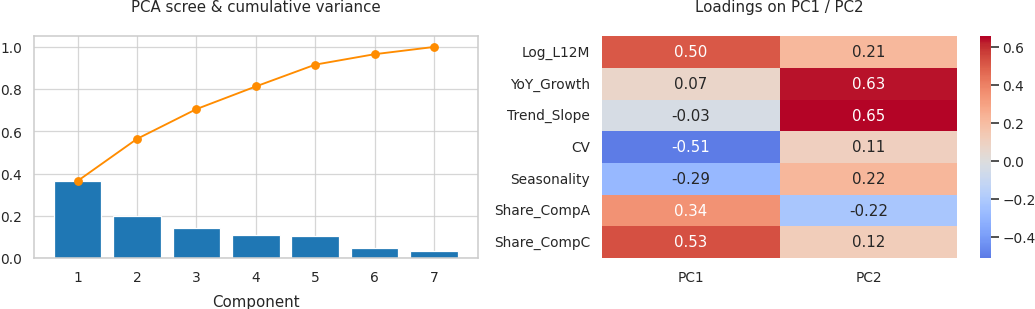

Hopkins statistic: 0.811
Cumulative variance: [0.366 0.565 0.706 0.813 0.916 0.966 1.   ]


In [10]:
def hopkins(Zv, m=None, seed=RANDOM_STATE, reps=10):
    Zv = np.asarray(Zv); n, d = Zv.shape; m = m or int(0.1 * n)
    r = np.random.default_rng(seed); nn = NearestNeighbors(n_neighbors=2).fit(Zv); out = []
    for _ in range(reps):
        idx = r.choice(n, m, replace=False)
        w = nn.kneighbors(Zv[idx], 2)[0][:, 1]
        u = nn.kneighbors(r.uniform(Zv.min(0), Zv.max(0), (m, d)), 1)[0][:, 0]
        out.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(out))

H = hopkins(Z)
pca_full = PCA().fit(Z)
cum = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color="#1f77b4"); ax[0].plot(range(1, len(cum) + 1), cum, "o-", color="darkorange")
ax[0].set_title("PCA scree & cumulative variance"); ax[0].set_xlabel("Component")
load = pd.DataFrame(pca_full.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Loadings on PC1 / PC2")
plt.tight_layout(); plt.show()
print(f"Hopkins statistic: {H:.3f}")
print("Cumulative variance:", np.round(cum, 3))

> **Insight —** Hopkins = 0.81 (well above 0.5), so the data has real non-random structure. PC1 (37 %) is a size/range/stability axis (Log_L12M, Share_CompC up; CV down) and PC2 (20 %) is a momentum axis (YoY growth, trend slope). Two components explain only 57 % of variance (five are needed for 92 %), so 2-D plots will show some overlap that is a projection effect.

## 8. Choosing DBSCAN parameters
DBSCAN has two hyper-parameters:
- **`min_samples`** – minimum neighbours (incl. the point itself) to form a dense core. A common rule is ≥ 2 × number of features (here 14) but small values (4–8) find finer structure.
- **`eps`** – neighbourhood radius in standardised units.

### 8.1 k-distance plot
For each point we compute the distance to its *min_samples*-th nearest neighbour and sort it. The "knee" of the curve suggests where points stop being dense (candidate `eps`).

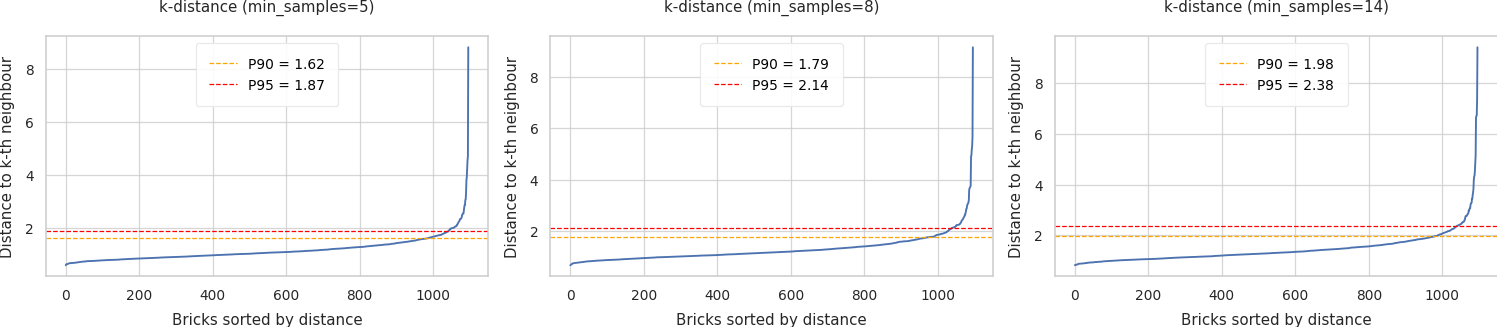

,P50,P75,P90,P95,P99
min_samples,,,,,
5,1.07,1.31,1.62,1.87,2.78
8,1.17,1.44,1.79,2.14,3.22
14,1.30,1.60,1.98,2.38,3.84


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
kd_tbl = {}
for a, ms in zip(ax, [5, 8, 14]):
    d, _ = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)
    kd = np.sort(d[:, -1]); kd_tbl[ms] = np.percentile(kd, [50, 75, 90, 95, 99])
    a.plot(kd); a.set_title(f"k-distance (min_samples={ms})"); a.set_xlabel("Bricks sorted by distance"); a.set_ylabel("Distance to k-th neighbour")
    for q, col in [(90, "orange"), (95, "red")]: a.axhline(np.percentile(kd, q), color=col, ls="--", lw=1, label=f"P{q} = {np.percentile(kd, q):.2f}")
    a.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(kd_tbl, index=["P50", "P75", "P90", "P95", "P99"]).T.round(2).rename_axis("min_samples"))

> **Insight —** The k-distance curves rise gradually with no sharp knee – a sign of one continuous density rather than separated groups. The 90th/95th percentile distances are 1.62/1.87 (min_samples 5), 1.79/2.14 (8) and 1.98/2.38 (14), so useful `eps` values lie roughly between 1.0 and 2.0 and must be tuned with a grid.

### 8.2 Parameter grid search
The k-distance curve has no sharp knee, so we search `eps` ∈ [0.40, 2.00] × `min_samples` ∈ {4, 5, 6, 8, 10, 14, 20}. For each combination we record number of clusters, noise share and quality metrics (computed on the clustered, non-noise points – DBSCAN's convention).

Combinations tried: 231 | with >=2 clusters: 79 | with >=1 cluster: 186


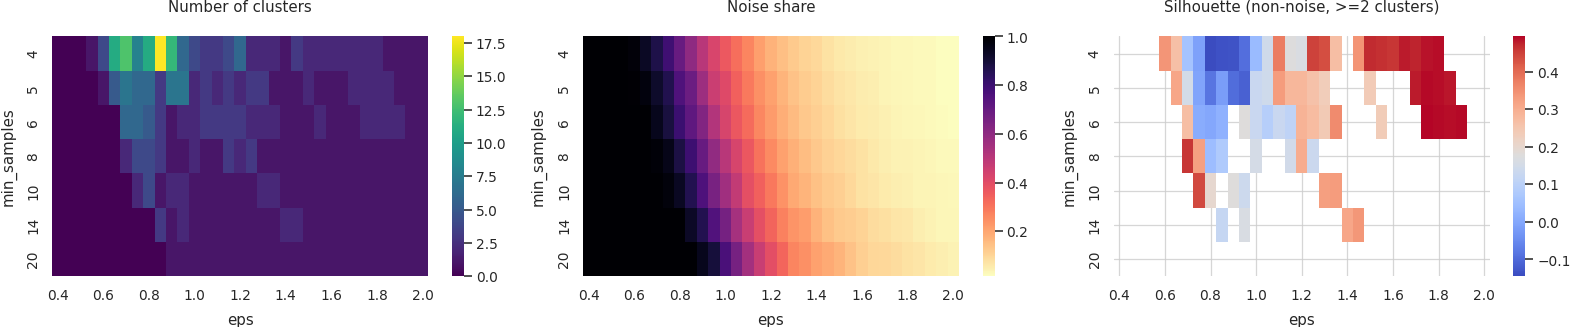

In [12]:
def db_eval(Zv, eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zv)
    m = lab != -1; nc = len(set(lab[m]))
    r = {"eps": round(eps, 2), "min_samples": ms, "clusters": nc, "noise_pct": 1 - m.mean(),
         "smallest_cluster": int(np.bincount(lab[m]).min()) if nc else 0,
         "largest_cluster_pct_of_clustered": (np.bincount(lab[m]).max() / m.sum()) if nc else np.nan,
         "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if nc >= 2:
        r["silhouette"] = silhouette_score(Zv[m], lab[m]); r["davies_bouldin"] = davies_bouldin_score(Zv[m], lab[m])
        r["calinski_harabasz"] = calinski_harabasz_score(Zv[m], lab[m])
    return r

grid = pd.DataFrame([db_eval(Z.values, e, ms) for ms in [4, 5, 6, 8, 10, 14, 20] for e in np.arange(0.40, 2.001, 0.05)])
print("Combinations tried:", len(grid), "| with >=2 clusters:", int((grid["clusters"] >= 2).sum()), "| with >=1 cluster:", int((grid["clusters"] >= 1).sum()))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (col, ttl, cm) in zip(ax, [("clusters", "Number of clusters", "viridis"), ("noise_pct", "Noise share", "magma_r"), ("silhouette", "Silhouette (non-noise, >=2 clusters)", "coolwarm")]):
    pv = grid.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(pv, ax=a, cmap=cm, cbar=True, xticklabels=4); a.set_title(ttl)
plt.tight_layout(); plt.show()

> **Insight —** Of 231 combinations only 79 yield ≥ 2 clusters. Noise falls steadily as eps grows (over 90 % below eps 0.65 → under 10 % above eps 1.7) and for eps > 1.0 the cluster count is mostly 1–3 (max 6); the many-cluster results (up to ~18) occur only at small eps with mostly-noise outcomes. The high-silhouette area at top-right of the third panel (~0.49) comes from clusters of only 5–7 bricks, which is why we constrain the search.

### 8.3 Selection rule
A solution is only useful if it (i) finds **at least 2 clusters**, (ii) leaves **no more than 30 % of bricks as noise** (otherwise most of the estate is unclassified), and (iii) has no degenerate micro-clusters (every cluster ≥ 1 % of bricks, i.e. ≥ 11). Among the eligible configurations we take the highest silhouette. (Without rule iii the grid happily picks a tiny 6-brick cluster that inflates silhouette.)

In [13]:
MIN_CLUSTER = int(np.ceil(0.01 * len(Z)))
elig = grid[(grid["clusters"] >= 2) & (grid["noise_pct"] <= 0.30) & (grid["smallest_cluster"] >= MIN_CLUSTER)].sort_values("silhouette", ascending=False)
display(elig.head(10).style.format({"noise_pct": "{:.1%}", "largest_cluster_pct_of_clustered": "{:.1%}", "silhouette": "{:.3f}", "davies_bouldin": "{:.2f}", "calinski_harabasz": "{:.0f}"}))
best = elig.iloc[0]; EPS, MS = float(best["eps"]), int(best["min_samples"])
print(f"-> Selected eps = {EPS:.2f}, min_samples = {MS}")

,eps,min_samples,clusters,noise_pct,smallest_cluster,largest_cluster_pct_of_clustered,silhouette,davies_bouldin,calinski_harabasz
186,1.450000,14,2,14.7%,28,97.0%,0.337,0.94,81
47,1.100000,5,2,29.0%,13,98.3%,0.332,0.84,40
151,1.350000,10,2,17.0%,24,97.4%,0.331,0.93,69
150,1.300000,10,2,19.3%,21,97.6%,0.326,0.91,60
185,1.400000,14,2,17.4%,18,98.0%,0.314,0.91,50


-> Selected eps = 1.45, min_samples = 14


> **Insight —** Best eligible setting: **eps = 1.45, min_samples = 14** (= 2 × 7 features, the classic rule) – 2 clusters, 14.7 % noise, smallest cluster 28 bricks, silhouette 0.337, Davies-Bouldin 0.94. All runners-up are also 2-cluster solutions; no setting gives 3+ meaningful clusters, so the data behaves like one dense mass plus a fringe.

## 9. Final DBSCAN model

In [14]:
db = DBSCAN(eps=EPS, min_samples=MS).fit(Z)
lab = db.labels_
F["DBSCAN_Cluster"] = lab
core_mask = np.zeros(len(Z), bool); core_mask[db.core_sample_indices_] = True
F["Point_Type"] = np.where(lab == -1, "Noise", np.where(core_mask, "Core", "Border"))
m = lab != -1; nc = len(set(lab[m]))

# silhouette variants: (a) clustered points only (standard), (b) noise treated as its own group (penalises noise)
sil_clustered = silhouette_score(Z[m], lab[m])
sil_all = silhouette_score(Z, lab)
metrics = {
    "model": "DBSCAN", "eps": EPS, "min_samples": MS, "n_bricks": int(len(Z)), "n_clusters": int(nc),
    "noise_n": int((~m).sum()), "noise_pct": float((~m).mean()), "coverage_pct": float(m.mean()),
    "silhouette_clustered_only": float(sil_clustered), "silhouette_noise_as_group": float(sil_all),
    "davies_bouldin": float(davies_bouldin_score(Z[m], lab[m])), "calinski_harabasz": float(calinski_harabasz_score(Z[m], lab[m])),
    "cluster_sizes": {int(k): int(v) for k, v in pd.Series(lab).value_counts().sort_index().items()},
}
display(pd.Series({k: v for k, v in metrics.items() if k != "cluster_sizes"}).to_frame("DBSCAN").T.round(3))
print("Label counts (-1 = noise):", metrics["cluster_sizes"])
print(F["Point_Type"].value_counts().to_string())

,model,eps,min_samples,n_bricks,n_clusters,noise_n,noise_pct,coverage_pct,silhouette_clustered_only,silhouette_noise_as_group,davies_bouldin,calinski_harabasz
DBSCAN,DBSCAN,1.45,14,1097,2,161,0.146764,0.853236,0.337355,0.249642,0.942065,81.335009


Label counts (-1 = noise): {-1: 161, 0: 908, 1: 28}
Point_Type
Core      713
Border    223
Noise     161


> **Insight —** DBSCAN labels 908 bricks as Cluster 0, 28 as Cluster 1 and 161 (14.7 %) as noise; coverage 85.3 %. Silhouette is 0.337 on clustered bricks and falls to 0.250 if noise is counted as its own group; Davies-Bouldin 0.94, Calinski-Harabasz 81. Points: 713 core, 223 border, 161 noise. Note 97 % of clustered bricks sit in one cluster, so the silhouette mostly measures 'core vs small fringe cluster'.

## 10. Cluster profiling
Profiles in **original business units**; `-1` is the noise group (bricks that belong to no dense region).

,Bricks,Avg_L12M_units,Median_L12M_units,YoY_Growth,Trend_Slope_pct_per_month,CV,Seasonality,CompA_share,CompB_share,CompC_share,Avg_pack_breadth,Pct_of_bricks,Pct_of_L12M_volume
DBSCAN_Cluster,,,,,,,,,,,,,
-1,161,313,107,-2.0%,+0.17%,0.20,1.17,13.6%,84.7%,1.7%,5.3,14.7%,7.5%
0,908,677,480,-0.8%,+0.17%,0.16,1.13,15.0%,79.9%,5.1%,6.8,82.8%,92.0%
1,28,100,99,-4.4%,+0.10%,0.18,1.13,14.5%,85.0%,0.5%,5.3,2.6%,0.4%


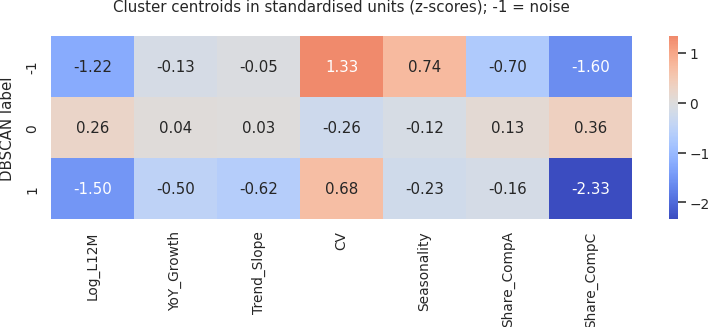

In [15]:
prof = F.groupby("DBSCAN_Cluster").agg(
    Bricks=("L12M", "size"), Avg_L12M_units=("L12M", "mean"), Median_L12M_units=("L12M", "median"),
    YoY_Growth=("YoY_Growth", "mean"), Trend_Slope_pct_per_month=("Trend_Slope", "mean"),
    CV=("CV", "mean"), Seasonality=("Seasonality", "mean"),
    CompA_share=("Share_CompA", "mean"), CompB_share=("Share_CompB", "mean"), CompC_share=("Share_CompC", "mean"),
    Avg_pack_breadth=("Pack_Breadth", "mean"))
prof["Pct_of_bricks"] = prof["Bricks"] / len(F)
prof["Pct_of_L12M_volume"] = F.groupby("DBSCAN_Cluster")["L12M"].sum() / F["L12M"].sum()
fmt = {"Avg_L12M_units": "{:,.0f}", "Median_L12M_units": "{:,.0f}", "YoY_Growth": "{:+.1%}", "Trend_Slope_pct_per_month": "{:+.2%}",
       "CV": "{:.2f}", "Seasonality": "{:.2f}", "CompA_share": "{:.1%}", "CompB_share": "{:.1%}", "CompC_share": "{:.1%}",
       "Avg_pack_breadth": "{:.1f}", "Pct_of_bricks": "{:.1%}", "Pct_of_L12M_volume": "{:.1%}"}
display(prof.style.format(fmt))
zc = Z.groupby(lab).mean()
plt.figure(figsize=(9, 2.2 + 0.6 * len(zc))); sns.heatmap(zc, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster centroids in standardised units (z-scores); -1 = noise"); plt.ylabel("DBSCAN label"); plt.tight_layout(); plt.show()

> **Insight —** **Cluster 0** is the mainstream: 908 bricks, 92 % of volume, ~677 units/brick, CV 0.16, Company C share 5.1 %, YoY −0.8 %. **Cluster 1** (28 bricks) is a low-volume fringe group (~100 units, 0.4 % of volume, almost no Company C, −4.4 %). **Noise** (161 bricks, 7.5 % of volume) has a mean of 313 units but a median of 107 – a mix of very small and a few very large bricks – with higher volatility (CV 0.20) and Company C share of only 1.7 %.

### 10.1 What makes a brick "noise"?
DBSCAN's most useful by-product is the list of outliers. We compare noise bricks with core-cluster bricks feature by feature (z-score gap) and look at the most extreme examples.

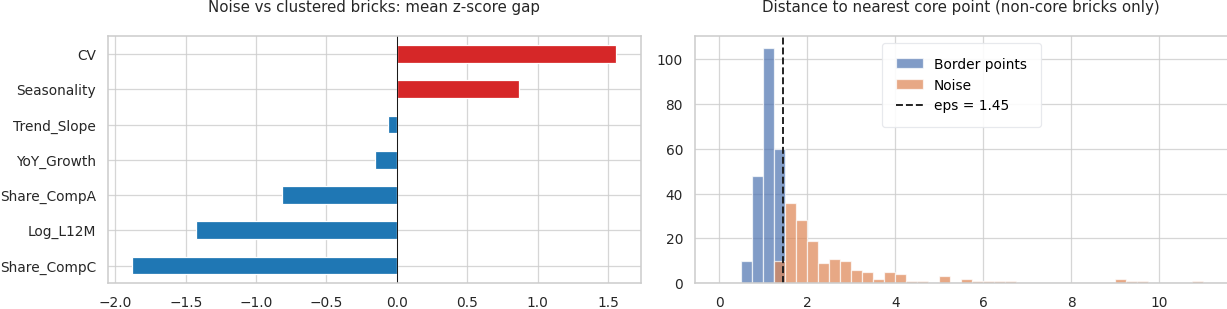

,State,L12M,YoY_Growth,CV,Seasonality,Share_CompA,Share_CompC,Pack_Breadth,Dist_to_core
Brick Name,,,,,,,,,
Brick 0184,QLD,11,+37.5%,1.03,1.67,0.0%,0.0%,2,11.00
Brick 0672,WA,19,-17.4%,0.38,1.31,0.0%,0.0%,2,9.58
Brick 0543,VIC,26,-25.7%,0.29,1.17,0.0%,0.0%,2,9.30
Brick 0182,VIC,24,-17.2%,0.31,1.18,0.0%,0.0%,2,9.06
Brick 0616,TAS,20,+5.3%,0.36,1.18,0.0%,0.0%,2,9.02
Brick 0756,NSW,27,-25.0%,0.30,1.22,7.4%,0.0%,3,6.72
Brick 0123,WA,31,-16.2%,0.28,1.21,6.5%,0.0%,4,6.32
Brick 0540,NSW,40,-14.9%,0.26,1.33,7.5%,0.0%,4,6.24
Brick 0064,NSW,31,-16.2%,0.26,1.11,6.5%,0.0%,3,5.95


Noise bricks: 161 | median L12M units 107 vs clustered 470 | share of total volume 7.5%


In [16]:
noise = F["DBSCAN_Cluster"] == -1
gap = (Z[noise].mean() - Z[~noise].mean()).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
gap.plot.barh(ax=ax[0], color=np.where(gap > 0, "#d62728", "#1f77b4")); ax[0].set_title("Noise vs clustered bricks: mean z-score gap"); ax[0].axvline(0, color="k", lw=.8)
dist_core = NearestNeighbors(n_neighbors=1).fit(Z[core_mask]).kneighbors(Z)[0][:, 0]
bins = np.linspace(0, dist_core.max(), 45)
ax[1].hist(dist_core[~core_mask & ~noise], bins=bins, alpha=.7, label="Border points"); ax[1].hist(dist_core[noise], bins=bins, alpha=.7, label="Noise")
ax[1].axvline(EPS, color="k", ls="--", label=f"eps = {EPS:.2f}"); ax[1].set_title("Distance to nearest core point (non-core bricks only)"); ax[1].legend()
plt.tight_layout(); plt.show()

F["Dist_to_core"] = dist_core
cols = ["State", "L12M", "YoY_Growth", "CV", "Seasonality", "Share_CompA", "Share_CompC", "Pack_Breadth", "Dist_to_core"]
display(F.loc[noise, cols].sort_values("Dist_to_core", ascending=False).head(10).style.format({"YoY_Growth": "{:+.1%}", "CV": "{:.2f}", "Seasonality": "{:.2f}", "Share_CompA": "{:.1%}", "Share_CompC": "{:.1%}", "Dist_to_core": "{:.2f}"}))
nz_ = F.loc[noise]
print(f"Noise bricks: {noise.sum()} | median L12M units {nz_['L12M'].median():.0f} vs clustered {F.loc[~noise, 'L12M'].median():.0f} | "
      f"share of total volume {nz_['L12M'].sum()/F['L12M'].sum():.1%}")

> **Insight —** Noise bricks are mostly distinguished by **no/low Company C presence** (z-gap ≈ −1.9), **low volume** (−1.4) and **high volatility** (+1.5). 111 of 161 sell under 150 units/year and 75 of the 92 bricks with zero Company C are noise; all 5 bricks with zero Company A are noise too. At the other end, 7 noise bricks exceed 1,500 units (incl. the two largest bricks, 7,513 and 6,134 units) – unusual in the opposite direction. The most extreme (e.g. Brick 0184, 11 units, CV 1.03) sell only two packs.

### 10.2 Visualising the clusters (PCA projection)

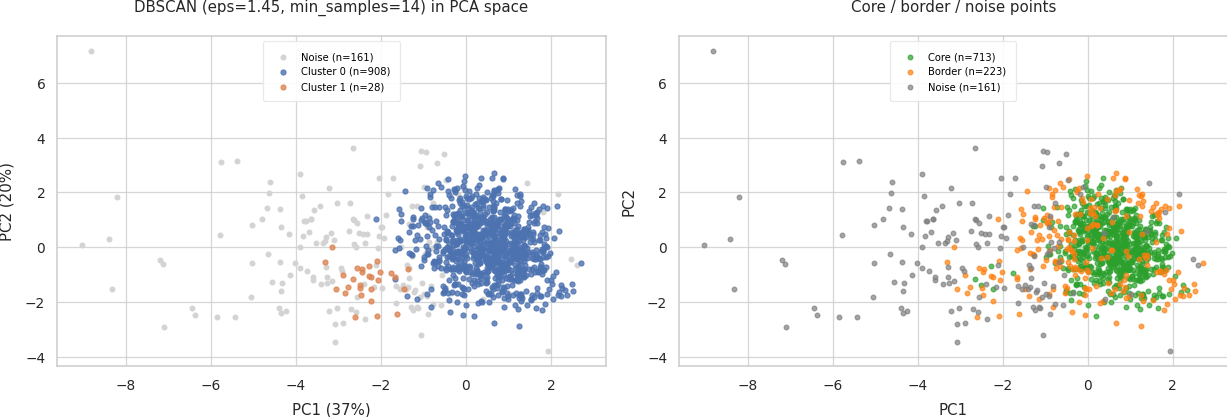

In [17]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z); P = pca2.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(P[lab == -1, 0], P[lab == -1, 1], c="lightgrey", s=14, label=f"Noise (n={int((lab == -1).sum())})")
for c in sorted(set(lab) - {-1}):
    ax[0].scatter(P[lab == c, 0], P[lab == c, 1], s=16, alpha=.8, label=f"Cluster {c} (n={int((lab == c).sum())})")
ax[0].set_title(f"DBSCAN (eps={EPS:.2f}, min_samples={MS}) in PCA space"); ax[0].legend(fontsize=8)
ax[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})"); ax[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
for t_, col in [("Core", "#2ca02c"), ("Border", "#ff7f0e"), ("Noise", "#7f7f7f")]:
    k_ = F["Point_Type"].values == t_; ax[1].scatter(P[k_, 0], P[k_, 1], s=14, c=col, alpha=.7, label=f"{t_} (n={k_.sum()})")
ax[1].set_title("Core / border / noise points"); ax[1].legend(fontsize=8); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

> **Insight —** The dense mainstream occupies the right-hand blob (core points in green); the 28-brick Cluster 1 forms a small pocket on its left flank, and noise forms a halo on the far left and around the edges. 223 border points (20 %) sit on the blob's periphery. DBSCAN draws a density boundary rather than slicing the blob, so it will not split growers from decliners.

## 11. Sensitivity & stability
DBSCAN can be fragile around `eps`. We (a) vary `eps` ± 0.20 around the chosen value, and (b) draw 25 random 80 % subsamples, re-run DBSCAN with the same parameters and compare to the full-data labels on the same bricks (ARI, noise treated as its own label).

In [18]:
sens = pd.DataFrame([db_eval(Z.values, e, MS) for e in np.round(np.arange(EPS - 0.30, EPS + 0.301, 0.10), 2)]).set_index("eps")
display(sens[["clusters", "noise_pct", "silhouette", "davies_bouldin"]].style.format({"noise_pct": "{:.1%}", "silhouette": "{:.3f}", "davies_bouldin": "{:.2f}"}))

aris, noise_agree = [], []
for b in range(25):
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    l2 = DBSCAN(eps=EPS, min_samples=MS).fit_predict(Z.iloc[idx])
    aris.append(adjusted_rand_score(lab[idx], l2)); noise_agree.append(((lab[idx] == -1) == (l2 == -1)).mean())
metrics["bootstrap_ARI"] = float(np.mean(aris)); metrics["bootstrap_ARI_std"] = float(np.std(aris))
print(f"Bootstrap ARI = {np.mean(aris):.3f} +/- {np.std(aris):.3f} | noise/non-noise agreement = {np.mean(noise_agree):.1%}")

,clusters,noise_pct,silhouette,davies_bouldin
eps,,,,
1.150000,1,39.0%,nan,nan
1.250000,1,27.6%,nan,nan
1.350000,1,21.7%,nan,nan
1.450000,2,14.7%,0.337,0.94
1.550000,1,11.8%,nan,nan
1.650000,1,8.8%,nan,nan
1.750000,1,6.7%,nan,nan


Bootstrap ARI = 0.911 +/- 0.018 | noise/non-noise agreement = 96.3%


> **Insight —** At fixed parameters the result is reproducible: bootstrap ARI 0.911 ± 0.018 and 96.3 % agreement on which bricks are noise. But it is **parameter-fragile**: in the ±0.30 eps neighbourhood only eps = 1.45 gives two clusters; 1.35 and 1.55 collapse to a single cluster, and noise swings from 39 % (eps 1.15) to 6.7 % (eps 1.75).

## 12. External validation against State
State was **not** a model input; we test whether DBSCAN groups (and noise) are geographically biased.

State,ACT,NSW,NT,QLD,SA,TAS,VIC,WA
DBSCAN_Cluster,,,,,,,,
-1,7,44,2,31,13,7,37,20
0,49,267,4,171,75,23,215,104
1,2,9,1,2,2,1,8,3


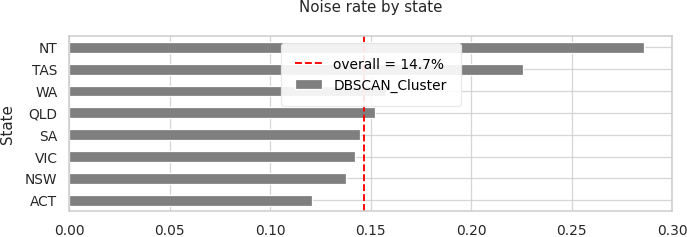

Cluster x State: chi-square p = 0.748 | Cramer's V = 0.068 | ARI = 0.003
Noise rate x State: chi-square p = 0.849


In [19]:
ct = pd.crosstab(F["DBSCAN_Cluster"], F["State"])
chi2, p, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
ari_state = adjusted_rand_score(F["State"], lab)
noise_rate = (F["DBSCAN_Cluster"] == -1).groupby(F["State"]).mean()
chi_n, p_n, _, _ = chi2_contingency(pd.crosstab(F["State"], F["DBSCAN_Cluster"] == -1))
display(ct)
fig, ax = plt.subplots(figsize=(8, 3)); noise_rate.sort_values().plot.barh(ax=ax, color="#7f7f7f"); ax.axvline(noise.mean(), color="red", ls="--", label=f"overall = {noise.mean():.1%}")
ax.set_title("Noise rate by state"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Cluster x State: chi-square p = {p:.3f} | Cramer's V = {cramers_v:.3f} | ARI = {ari_state:.3f}")
print(f"Noise rate x State: chi-square p = {p_n:.3f}")
metrics.update({"chi2_p_state": float(p), "cramers_v_state": float(cramers_v), "ari_vs_state": float(ari_state), "chi2_p_noise_by_state": float(p_n)})

> **Insight —** Neither clusters (chi-square p = 0.75, Cramér's V = 0.07, ARI 0.003) nor the noise flag (p = 0.85 across states) depend on state – DBSCAN does not penalise any particular region.

## 13. Business interpretation

In [20]:
LABEL_NAMES = {-1: "Atypical / Outlier Bricks", 0: "Mainstream Core", 1: "Low-Volume Fringe"}
F["DBSCAN_Segment"] = F["DBSCAN_Cluster"].map(LABEL_NAMES)
summary = F.groupby(["DBSCAN_Cluster", "DBSCAN_Segment"]).agg(Bricks=("L12M", "size"), L12M_units=("L12M", "sum"),
          Avg_units_per_brick=("L12M", "mean"), YoY=("YoY_Growth", "mean")).reset_index()
summary["Volume_share"] = summary["L12M_units"] / summary["L12M_units"].sum()
display(summary.style.format({"L12M_units": "{:,.0f}", "Avg_units_per_brick": "{:,.0f}", "YoY": "{:+.1%}", "Volume_share": "{:.1%}"}))

,DBSCAN_Cluster,DBSCAN_Segment,Bricks,L12M_units,Avg_units_per_brick,YoY,Volume_share
0,-1,Atypical / Outlier Bricks,161,"50,367",313,-2.0%,7.5%
1,0,Mainstream Core,908,"615,029",677,-0.8%,92.0%
2,1,Low-Volume Fringe,28,"2,795",100,-4.4%,0.4%


> **Insight —** Interpretation: **Mainstream Core** (908 bricks, 92 % of volume) is the planning baseline; **Low-Volume Fringe** (28) and **Atypical Bricks** (161, 7.5 % of volume) are exceptions to review – small/volatile bricks and a handful of unusually large ones that merit individual attention rather than a blanket rule.

## 14. Save artefacts

In [21]:
F[["State", "L12M", "P12M"] + FEATURES + ["DBSCAN_Cluster", "DBSCAN_Segment", "Point_Type", "Dist_to_core"]].to_csv("artifacts/dbscan_labels.csv")
json.dump(metrics, open("artifacts/dbscan_metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))

{
  "model": "DBSCAN",
  "eps": 1.45,
  "min_samples": 14,
  "n_bricks": 1097,
  "n_clusters": 2,
  "noise_n": 161,
  "noise_pct": 0.14676390154968094,
  "coverage_pct": 0.853236098450319,
  "silhouette_clustered_only": 0.3373554970906802,
  "silhouette_noise_as_group": 0.2496422191539363,
  "davies_bouldin": 0.9420645164246914,
  "calinski_harabasz": 81.3350091759795,
  "cluster_sizes": {
    "-1": 161,
    "0": 908,
    "1": 28
  },
  "bootstrap_ARI": 0.9111621523019546,
  "bootstrap_ARI_std": 0.01794203920453607,
  "chi2_p_state": 0.7479431324708372,
  "cramers_v_state": 0.06816040248120761,
  "ari_vs_state": 0.002884732604225786,
  "chi2_p_noise_by_state": 0.8492398668560184
}


> **Insight —** Labels (with core/border/noise flag and distance to core) and metrics are saved in `artifacts/` for the comparison notebook.

## 15. Conclusions & caveats
- **Result:** DBSCAN (eps = 1.45, min_samples = 14) finds a dominant **Mainstream Core** (908 bricks, 92 % of volume), a small **Low-Volume Fringe** (28 bricks) and flags **161 bricks (14.7 %) as noise**.
- **Quality:** silhouette 0.337 (0.250 with noise as its own group), Davies-Bouldin 0.94, Calinski-Harabasz 81, bootstrap ARI 0.91.
- **Strength:** natively isolates atypical bricks (tiny/volatile ones and a few extreme-volume ones) without forcing them into a segment; no geographic bias (ARI vs state 0.003).
- **Weakness:** it does not segment the mainstream – 97 % of clustered bricks fall in one cluster – and the 2-cluster solution exists only at eps ≈ 1.45 (adjacent values give one cluster).
- **Caveats:** silhouette is computed on clustered bricks only and is flattered by the dominant cluster; synthetic data.